# D6 — Human evaluation of explanation formats (materials only)

> **STATUS: NO PARTICIPANT DATA EXISTS.** This notebook shows the *materials* for the pre-registered human study. Nothing here simulates, imputes or invents participant responses. The analysis section stays empty until real sessions with CSO engineers have taken place, under the prerequisites in `reports/d6_human_study_protocol.md` §2: ethics approval, supervisor approval and informed consent.

**Design** (Study D addendum, commit c0a3ee1; full protocol in `reports/d6_human_study_protocol.md`):
- **Within-subject**, six explanation formats:
  - F0: score only (control);
  - F1: SHAP waterfall;
  - F2: LIME bars;
  - F3: group-level summary;
  - F4: EBM shape terms;
  - F5: counterfactual / EPSS trigger.
- 24 public CVEs in 3 rank strata (top-10, rank 11–500, below 500) × 8, split into 6 blocks.
- A 6×6 Williams Latin square balances format order and carry-over.
- **Measures:**
  - T1: forward simulation, "will the model place it in the top-100?";
  - T2: top factor;
  - escalation decision;
  - trust (1–7);
  - decision time.
- **Planned n = 12.** The minimum detectable paired effect is d_z 0.91 at α 0.05 and 1.19 at α 0.01 (power 0.8).
- **No internal data:** every stimulus is a public CVE (NVD + EPSS + CISA KEV).

Run: `python -m src.explainability.human_study` (needs D2 attributions and the D4 EBM).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

## (1) Williams Latin square: format per participant group × CVE block

In [2]:
pd.read_csv("outputs/d6_latin_square.csv", index_col=0)

,block_1,block_2,block_3,block_4,block_5,block_6
group_1,F0,F1,F5,F2,F4,F3
group_2,F1,F2,F0,F3,F5,F4
group_3,F2,F3,F1,F4,F0,F5
group_4,F3,F4,F2,F5,F1,F0
group_5,F4,F5,F3,F0,F2,F1
group_6,F5,F0,F4,F1,F3,F2


## (2) Stimuli and answer key (never shown to participants)

In [3]:
s = pd.read_csv("outputs/d6_stimuli.csv")
print(pd.crosstab(s.block, s.stratum))
s

stratum  below 500  rank 11-500  top-10
block                                  
block_1          1            1       2
block_2          1            1       2
block_3          1            2       1
block_4          1            2       1
block_5          2            1       1
block_6          2            1       1


,cve_id,month,stratum,block,kev,xgb_rank,month_size,T1_in_top100_xgb,T1_in_top100_ebm,ebm_rank,T2_top_factor_F1_F5,T2_top_factor_F2,T2_top_factor_F4,T2_top_group_F0_F3
0,CVE-2025-49113,2025-07,top-10,block_1,1,1,3792,True,True,2,epss_pit,cvss_version,cvss_version,EPSS
1,CVE-2023-6623,2024-02,top-10,block_1,0,6,2638,True,True,86,cvss_version,cvss_version,cvss_version,CVSS
2,CVE-2025-29635,2025-04,rank 11-500,block_1,1,445,4149,False,False,473,cvss_version,cvss_version,cvss_version,CVSS
3,CVE-2026-83353,2026-10,below 500,block_1,0,6178,15048,False,False,4743,cvss_version,epss_pit,cvss_version,CVSS
4,CVE-2024-49074,2025-01,top-10,block_2,0,4,3432,True,True,18,cvss_version,cvss_version,cvss_version,CVSS
5,CVE-2023-23531,2023-03,top-10,block_2,0,10,2467,True,True,2,cvss_version,cvss_version,cvss_version,CVSS
6,CVE-2025-43510,2026-01,rank 11-500,block_2,1,22,5629,True,True,12,cvss_version,cvss_version,cvss_version,CVSS
7,CVE-2024-32454,2024-05,below 500,block_2,0,1924,3726,False,False,1517,cvss_version,epss_pit,cvss_version,CVSS
8,CVE-2024-21446,2024-04,top-10,block_3,0,7,3348,True,True,10,cvss_version,cvss_version,cvss_version,CVSS
9,CVE-2025-31277,2025-08,rank 11-500,block_3,1,29,3925,True,True,7,cvss_version,cvss_version,cvss_version,CVSS


Strata are balanced across blocks: each block has 4 CVEs, and every stratum appears 8 times in total. The answer key gives the correct T1 answer separately for the XGBoost model (used by formats F0–F3 and F5) and for the EBM (F4), because F4 explains a different model. The cards do not show KEV status.

## (3) One example card per format

144 cards in outputs/d6_stimulus_cards.html



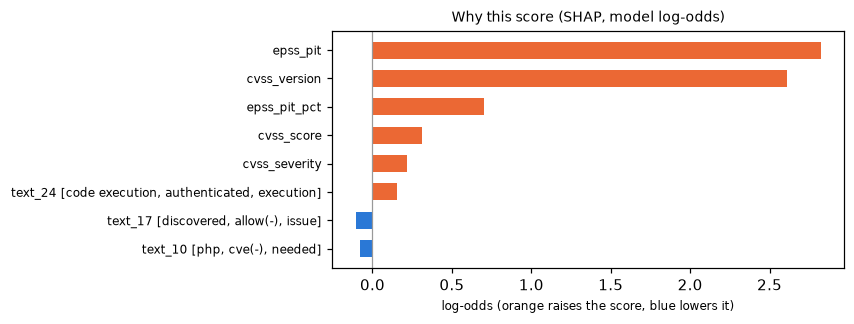
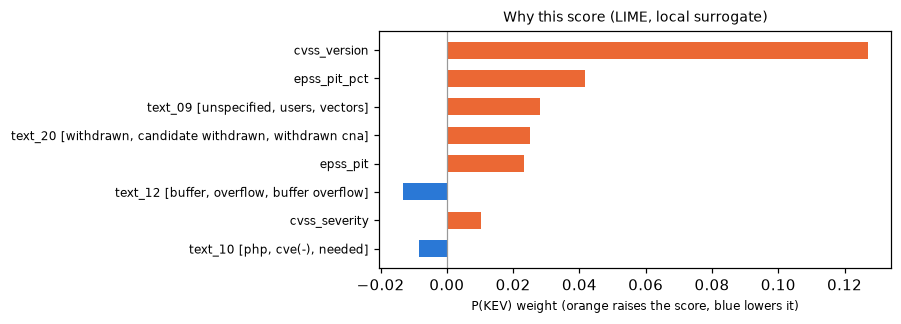
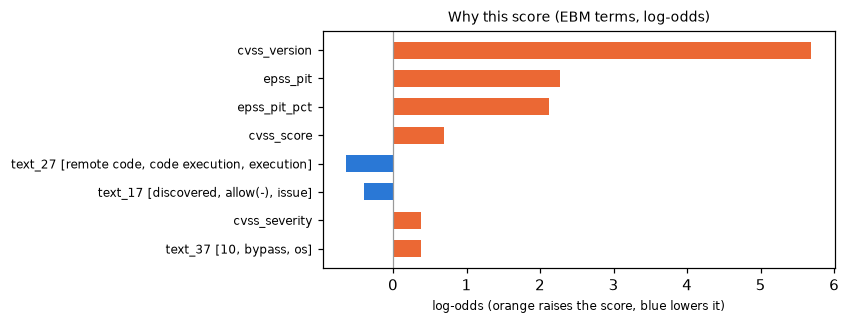

In [4]:
import re
from IPython.display import HTML
h = open("outputs/d6_stimulus_cards.html").read()
cards = re.findall(r"<section class='card'>.*?</section>", h, flags=re.S)
print(f"{len(cards)} cards in outputs/d6_stimulus_cards.html")
first = cards[:6]  # the first CVE in all six formats
HTML("<style>.card{border:1px solid #ccc;border-radius:8px;padding:1rem;margin:1rem 0}img{max-width:100%}</style>" + "".join(first))

## (4) Analysis — NOT RUN (no data)

Fixed in advance in protocol §7. Per participant × format, scores are averaged over that format's four trials.
- **Primary outcome:** T1 forward-simulation accuracy.
- **Across the six formats:** Friedman test, then Nemenyi.
- **Each format vs F0:** Wilcoxon signed-rank, Holm-adjusted over the five comparisons.
- **Effect sizes:** matched-pairs rank-biserial r, with 95% CI.
- **Secondary, labelled exploratory:** T2 accuracy, decision time, trust, appropriate reliance (T3 agreement with the KEV outcome), and trust calibration. Same tests, not Holm-adjusted across measures.
- **Exclusions:** a participant who fails both training checks or completes fewer than 18 of 24 trials.
- **Negative result** (protocol §8): no format beats F0 on T1 or T2. That would be a finding for SQ2, not a failure of the study.

This section is filled in only once real responses exist.